In [1]:
import pandas as pd
import glob
from pathlib import Path
import json
import os
import sys
sys.path.append("..")

import wandb
api = wandb.Api()

wandb: Currently logged in as: zanderman (zanderman-virginia-tech) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [2]:
project_id = "qnrl"

In [3]:
# sweeps = api.project(project_id).sweeps()

In [4]:
# [dict(name=s.name, id=s.id) for s in sweeps]

In [5]:
# List of sweep names and their IDs for reference.
sweep_name_id = { # name: id
    'qnrl/FrozenLake-v1': 'oi7rm7sh',
    'qnrl/CliffWalking-v1': '2f7ji0uu',
    'qnrl/Acrobot-v1': '28tqdi2r',
    'qnrl/CartPole-v1': '0xhzu1tq',
    'c51/FrozenLake-v1': '6ebrrbwp',
    'c51/CliffWalking-v1': '0nxxo52o',
    'c51/Acrobot-v1': '2ti1laob',
    'c51/CartPole-v1': 'mjqmhnd0',
}

In [6]:
root_sweeps = Path("../wandb-sweep-data/")
root_sweeps.mkdir(parents=True, exist_ok=True)

In [7]:
import ast
from qnrl.serialization import hash_serializable_object
def get_run_config_dict_from_metadata(metadata_file: Path):
    """Compute run config hash from original run program command string."""
    # Load metadata as JSON dictionary.
    with open(str(metadata_file), 'r') as f:
        metadata = json.load(f)
    
    # Get config string from run program command arguments.
    # Format is: --config="{...}"
    cfg_str = metadata['args'][1].split("--config=")[1]
    # Convert this string to dictionary via literal evaluation.
    cfg_dict = ast.literal_eval(cfg_str)
    return cfg_dict

In [8]:
metadata_path_tree = {
    # Each sweep has a dictionary of runs.
    Path(sweep_dir).stem.split('sweep-')[1]: {
        # Each run has a list of parquet files.
        Path(run_dir).stem.split('run-')[1]: glob.glob(str(Path(run_dir)/'wandb-metadata.json')) for run_dir in glob.glob(str(Path(sweep_dir)/'*'))
    } for sweep_dir in glob.glob(str(root_sweeps/'*'))
}

In [9]:
history_path_tree = {
    # Each sweep has a dictionary of runs.
    Path(sweep_dir).stem.split('sweep-')[1]: {
        # Each run has a list of parquet files.
        Path(run_dir).stem.split('run-')[1]: glob.glob(str(Path(run_dir)/'*.parquet')) for run_dir in glob.glob(str(Path(sweep_dir)/'*'))
    } for sweep_dir in glob.glob(str(root_sweeps/'*'))
}

In [10]:
from collections import defaultdict

def group_runs_by_base_config_hash(metadata_run_tree: dict[str, list[str]]):
    """Group a tree of runs by their base config hash (i.e., without seed) using run metadata file."""
    seedgroups_tree = defaultdict(list)
    for run_id, metadata_paths in metadata_run_tree.items():
        # Now compute hash without seed in config dict to determine base config seed group.
        if metadata_paths:
            cfg_dict = get_run_config_dict_from_metadata(Path(metadata_paths[0]))
            cfg_dict_without_seed = cfg_dict.copy()
            _ = cfg_dict_without_seed.pop('seed', None)
            cfg_hash_without_seed, _ = hash_serializable_object(cfg_dict_without_seed)
            seedgroups_tree[cfg_hash_without_seed].append(run_id)
    return dict(seedgroups_tree) # Convert to regular dictionary.

# Group all runs for all seeds.
seedgroups_tree = {sweep_id: group_runs_by_base_config_hash(run_tree) for sweep_id, run_tree in metadata_path_tree.items()}

## Plot Functions

In [167]:
import matplotlib.pyplot as plt
import numpy as np


def generate_figure_from_meta(figure_meta: dict):
    match figure_meta['type']:
        case 'line-agg-mean':
            return generate_figure_line_agg_mean(figure_meta)
        case 'bar' | 'barh':
            return generate_figure_bar(figure_meta)


def generate_figure_line_agg_mean(figure_meta: dict):
    
    
    fig, ax = plt.subplots(figsize=figure_meta.get('figsize', None))
    # fig.suptitle(figure_meta['title'])
    fig.suptitle(figure_meta.get('title', ''))

    cmap = plt.get_cmap()
    colors_idx = np.linspace(0, 1, len(figure_meta['series']))
    
    data = {}

    for i, series_meta in enumerate(figure_meta['series']):
        sweep_id = series_meta['sweep']
        run_ids = series_meta['runs']
        label = series_meta['label']
        
        dfs = [
            # Each run can have multiple parquet files, so read them all in sequence.
            pd.concat(pd.read_parquet(parquet_file) for parquet_file in history_path_tree[sweep_id][run_id])
            for run_id in run_ids
        ]
        
        key_x = series_meta['x']
        key_y = series_meta['y']
        df = pd.concat({r: d[[key_x, key_y]].dropna().set_index(key_x) for r,d in zip(run_ids, dfs)}, axis=1)
        df.index = df.index.astype(int)
        df.columns = df.columns.reorder_levels([1, 0]) # make column indexing ["metric_key"]["run"]
        df = df.sort_index() # Combining train steps may leave DF not sorted, so sort by index to ensure monotonically increasing.
        
        x = df.index
        color = series_meta.get('color', cmap(colors_idx[i]))
        data_mean = (df[key_y].rolling(window=series_meta['window'], min_periods=1).mean()).mean(axis=1)
        data_min = (df[key_y].rolling(window=series_meta['window'], min_periods=1).mean()).min(axis=1)
        data_max = (df[key_y].rolling(window=series_meta['window'], min_periods=1).mean()).max(axis=1)
        ax.plot(x, data_mean, c=color, label=label, zorder=series_meta['zorder'])
        
        fill_between_kwargs = {
            'interpolate': True,
            'alpha': 0.3,
            'color': color,
        }
        if 'fill_between' in series_meta:
            if series_meta['fill_between'] is None:
                fill_between_kwargs = None
            else:
                fill_between_kwargs = {**fill_between_kwargs, **series_meta['fill_between']}
        if fill_between_kwargs is not None:
            ax.fill_between(x=x, y1=data_min, y2=data_max, **fill_between_kwargs)
        
        data[label] = {
            'mean': data_mean,
            'min': data_min,
            'max': data_max,
        }

    ax_kwargs = figure_meta.get('ax', {})
    
    legend_kwargs = {
        **{'loc': 'best'},
        **ax_kwargs.get('legend', {}),
    }
    ax.legend(**legend_kwargs)
    
    ax.set_title(ax_kwargs.get('title', ''))
    
    return fig, data


def generate_figure_bar(figure_meta: dict):
    
    fig, ax = plt.subplots(figsize=figure_meta.get('figsize', None))
    fig.suptitle(figure_meta.get('title', ''))
    
    bar_names = []
    bar_values = []
    bar_colors = []
    
    cmap = plt.get_cmap()
    colors_idx = np.linspace(0, 1, len(figure_meta['series']))
    
    data = {}
    
    for i, series_meta in enumerate(figure_meta['series']):
        sweep_id = series_meta['sweep']
        run_ids = series_meta['runs']
        label = series_meta['label']
        
        dfs = [
            # Each run can have multiple parquet files, so read them all in sequence.
            pd.concat(pd.read_parquet(parquet_file) for parquet_file in history_path_tree[sweep_id][run_id])
            for run_id in run_ids
        ]
        
        key_y = series_meta['y']
        color = series_meta.get('color', cmap(colors_idx[i]))
        # df = pd.concat({r: d[[key_y]].dropna() for r,d in zip(run_ids, dfs)}, axis=1)
        df = pd.concat({r: d[[key_y]].dropna() for r,d in zip(run_ids, dfs)}, axis=1)
        df.index = df.index.astype(int)
        df.columns = df.columns.reorder_levels([1, 0]) # make column indexing ["metric_key"]["run"]
        df = df.sort_index() # Combining train steps may leave DF not sorted, so sort by index to ensure monotonically increasing.
        
        # x = df.index
        bar_data = {
            'mean': (df[key_y].mean()).mean(),
            'min': (df[key_y].mean()).min(),
            'max': (df[key_y].mean()).max(),
            # 'std': (df[key_y].mean()).std(),
            'std': (df[key_y].std()).std(),
        }
        bar_names.append(label)
        bar_values.append(bar_data)
        bar_colors.append(color)
        
        data[label] = bar_data

    idx = list(range(len(bar_names)))
    if figure_meta['type'] == 'barh':
        b = ax.barh(idx, [d['mean'] for d in bar_values], yerr=[d['std'] for d in bar_values], color=bar_colors)
        ax.set_yticks(idx, labels=bar_names)
        ax.invert_yaxis()
    else:
        labels = [f"{key} ({d['mean']:.02f})" for key, d in data.items()]
        b = ax.bar(idx, [d['mean'] for d in bar_values], yerr=[d['std'] for d in bar_values], color=bar_colors, label=labels)
        
        xticks_kwargs = figure_meta['ax'].get('xticks', {})
        ax.set_xticks(idx, labels=bar_names, **xticks_kwargs)
    if 'bar-label' in figure_meta:
        ax.bar_label(b, **figure_meta['bar-label'])
    

    ax_kwargs = figure_meta.get('ax', {})
    
    legend_kwargs = {
        **{'loc': 'best'},
        **ax_kwargs.get('legend', {}),
    }
    ax.legend(**legend_kwargs)
    
    ax.set_title(ax_kwargs.get('title', ''))
    return fig, data

In [12]:
# print(sweep_name_id['c51/CliffWalking-v1'])
# # print(json.dumps(seedgroups_tree[sweep_name_id['c51/CliffWalking-v1']], indent=2))
# [v for k,v in seedgroups_tree[sweep_name_id['c51/CliffWalking-v1']].items() if "jg9cmu9e" in v][0]

## CliffWalking-v1

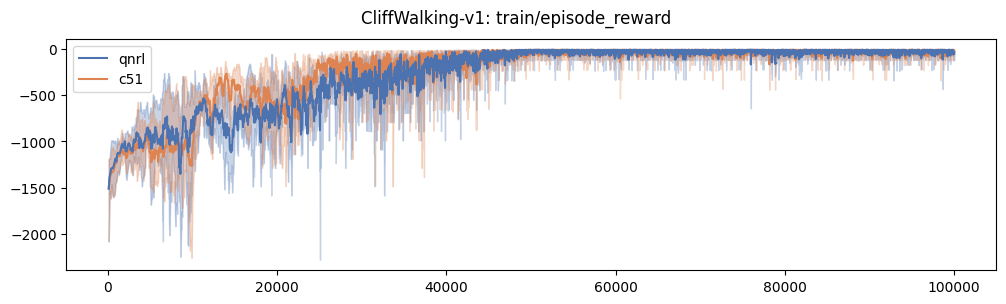

In [ ]:
figure_meta = {
    'type': 'line-agg-mean',
    'title': "CliffWalking-v1: train/episode_reward",
    'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CliffWalking-v1'], 
            'runs': ['a8o64lpl', 'wqe7o1tm', '64qrn97p', 'puue17pc'],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CliffWalking-v1'],
            'runs': ['odmbfmtl', 'jg9cmu9e', 'qiod5fx5', 'si5khh7f'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


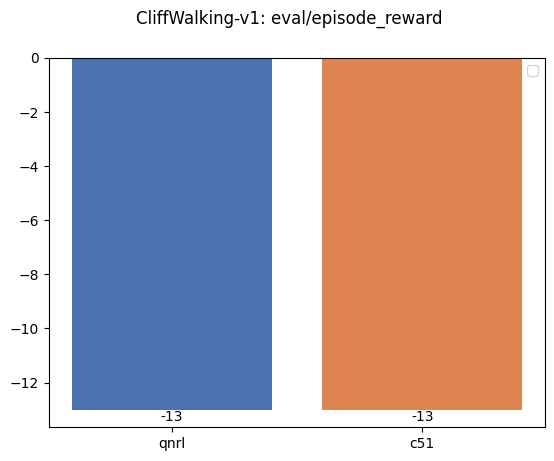

In [14]:
figure_meta = {
    'type': 'bar',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "CliffWalking-v1: eval/episode_reward",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CliffWalking-v1'], 
            'runs': ['a8o64lpl', 'wqe7o1tm', '64qrn97p', 'puue17pc'],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CliffWalking-v1'],
            'runs': ['odmbfmtl', 'jg9cmu9e', 'qiod5fx5', 'si5khh7f'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'y': 'eval/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


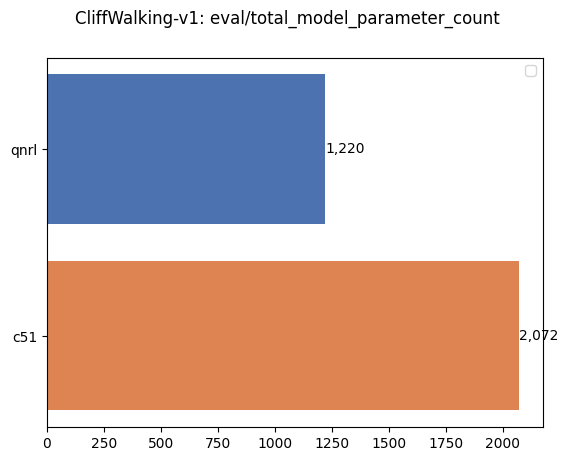

In [15]:
figure_meta = {
    'type': 'barh',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "CliffWalking-v1: eval/total_model_parameter_count",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CliffWalking-v1'], 
            'runs': ['a8o64lpl', 'wqe7o1tm', '64qrn97p', 'puue17pc'],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CliffWalking-v1'],
            'runs': ['odmbfmtl', 'jg9cmu9e', 'qiod5fx5', 'si5khh7f'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

## FrozenLake-v1

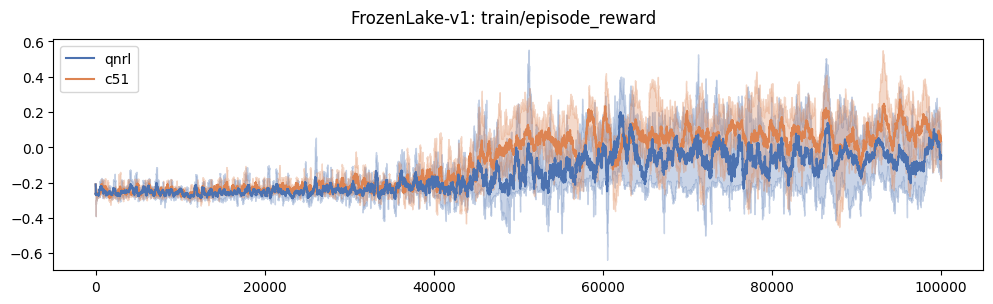

In [ ]:
figure_meta = {
    'type': 'line-agg-mean',
    'title': "FrozenLake-v1: train/episode_reward",
    'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/FrozenLake-v1'], 
            'runs': ["kk3m17os","v4ehm3m6","s9anekal","61ybwx42"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 100,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/FrozenLake-v1'],
            'runs': ['v4coevxe', 'dri04j3t', 'yfxlq3lq', 'tsu3eks7'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 100,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


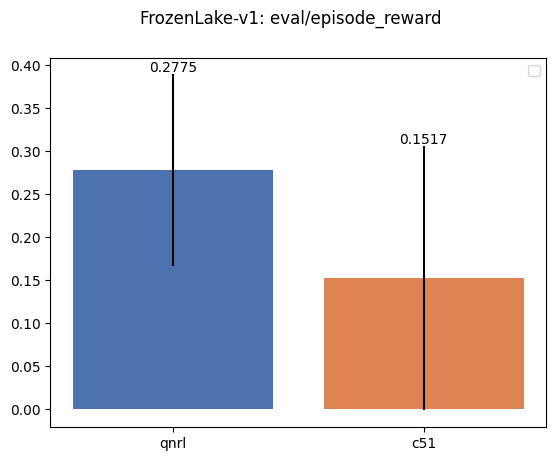

In [ ]:
figure_meta = {
    'type': 'bar',
    'bar-label': {
        'fmt': '{:,.04f}',
        'label_type': 'edge',
    },
    'title': "FrozenLake-v1: eval/episode_reward",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/FrozenLake-v1'], 
            'runs': ["kk3m17os","v4ehm3m6","s9anekal","61ybwx42"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 100,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/FrozenLake-v1'],
            'runs': ['v4coevxe', 'dri04j3t', 'yfxlq3lq', 'tsu3eks7'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 100,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


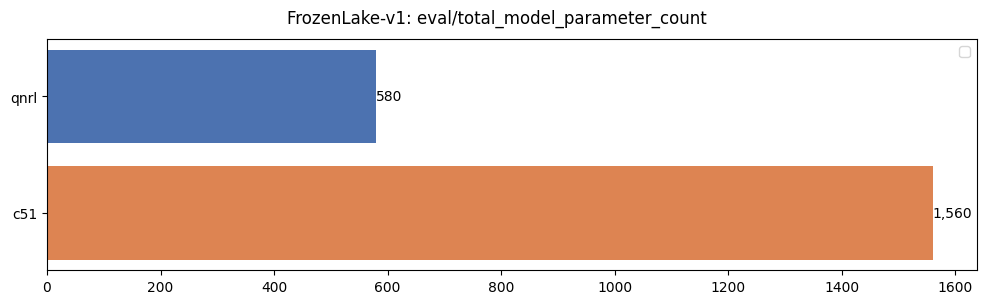

In [ ]:
figure_meta = {
    'type': 'barh',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "FrozenLake-v1: eval/total_model_parameter_count",
    'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/FrozenLake-v1'], 
            'runs': ["kk3m17os","v4ehm3m6","s9anekal","61ybwx42"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'eval/step',
            'y': 'eval/total_model_parameter_count',
            'window': 100,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/FrozenLake-v1'],
            'runs': ['v4coevxe', 'dri04j3t', 'yfxlq3lq', 'tsu3eks7'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'eval/step',
            'y': 'eval/total_model_parameter_count',
            'window': 100,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

## Acrobot-v1

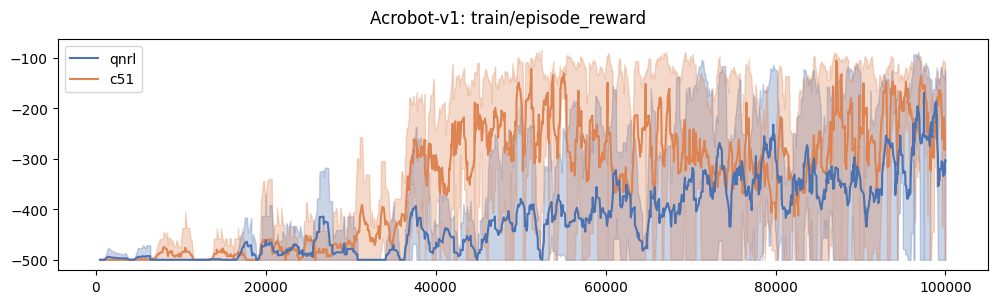

In [ ]:
figure_meta = {
    'type': 'line-agg-mean',
    'title': "Acrobot-v1: train/episode_reward",
    'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/Acrobot-v1'], 
            'runs': ["r8msd7sc","mxxij3w9","bobolhcz", "2nime9b4"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/Acrobot-v1'],
            'runs': ["6zaqh2d7","ubvoqjre","0w9w3jcy","w849ao6j"],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


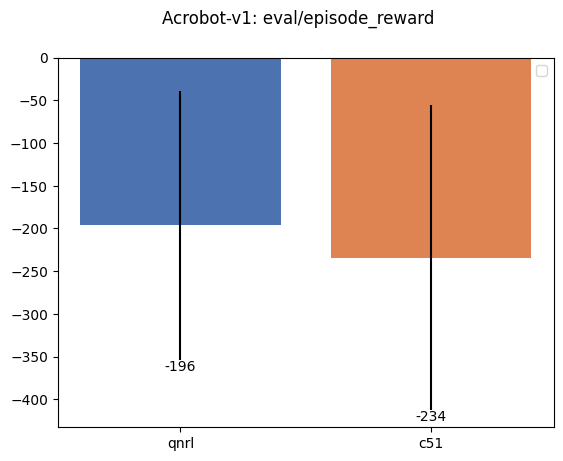

In [ ]:
figure_meta = {
    'type': 'bar',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "Acrobot-v1: eval/episode_reward",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/Acrobot-v1'], 
            'runs': ["r8msd7sc","mxxij3w9","bobolhcz", "2nime9b4"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/Acrobot-v1'],
            'runs': ["6zaqh2d7","ubvoqjre","0w9w3jcy","w849ao6j"],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


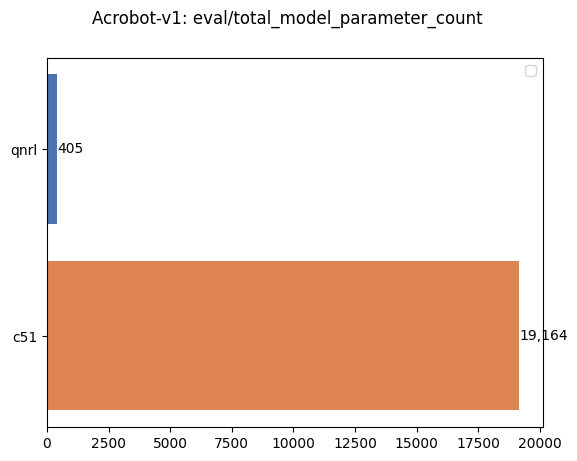

In [ ]:
figure_meta = {
    'type': 'barh',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "Acrobot-v1: eval/total_model_parameter_count",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/Acrobot-v1'], 
            'runs': ["r8msd7sc","mxxij3w9","bobolhcz", "2nime9b4"],
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/Acrobot-v1'],
            'runs': ["6zaqh2d7","ubvoqjre","0w9w3jcy","w849ao6j"],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

## CartPole-v1

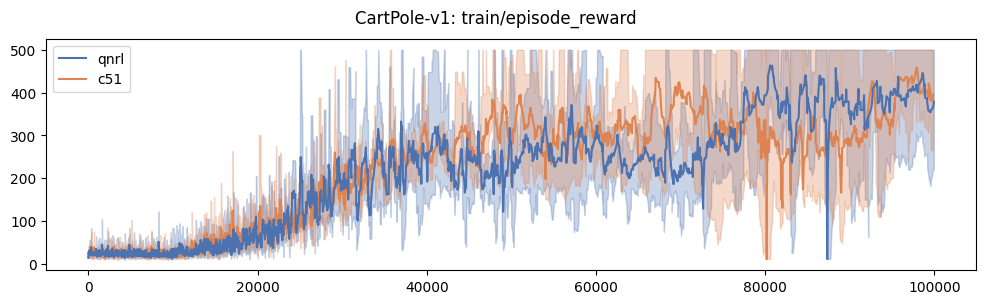

In [ ]:
figure_meta = {
    'type': 'line-agg-mean',
    'title': "CartPole-v1: train/episode_reward",
    'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': ['mgjghmmo','g9yukrth','z01m6pve','222yzgba'], 
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
        
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CartPole-v1'],
            'runs': ['glzv40eb','slzhggyr','dyplq20x','3tvkhxae'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


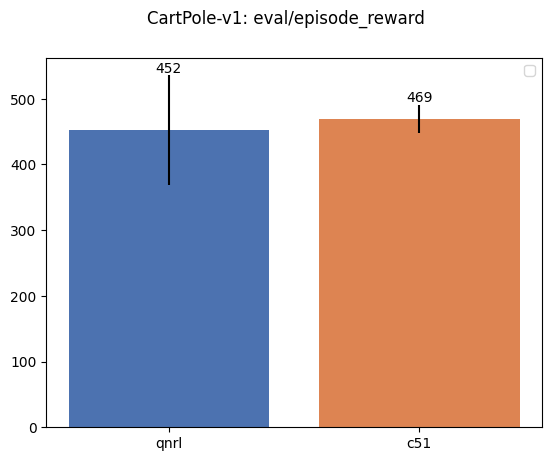

In [ ]:
figure_meta = {
    'type': 'bar',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "CartPole-v1: eval/episode_reward",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': ['mgjghmmo','g9yukrth','z01m6pve','222yzgba'], 
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 10,
        },
        
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CartPole-v1'],
            'runs': ['glzv40eb','slzhggyr','dyplq20x','3tvkhxae'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'eval/step',
            'y': 'eval/episode_reward',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_56966/1983909037.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='best')


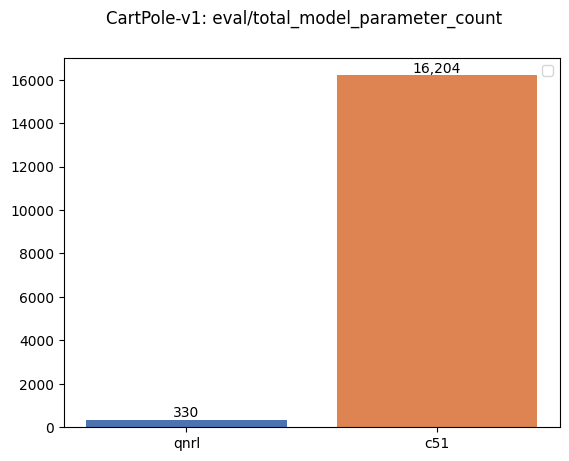

In [ ]:
figure_meta = {
    'type': 'bar',
    'bar-label': {
        'fmt': '{:,.0f}',
        'label_type': 'edge',
    },
    'title': "CartPole-v1: eval/total_model_parameter_count",
    # 'figsize': (12,3),
    'series': [
        {
            'label': 'qnrl',
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': ['mgjghmmo','g9yukrth','z01m6pve','222yzgba'], 
            'color': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
            'zorder': 2,
            'x': 'eval/step',
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
        
        {
            'label': 'c51',
            'sweep': sweep_name_id['c51/CartPole-v1'],
            'runs': ['glzv40eb','slzhggyr','dyplq20x','3tvkhxae'],
            'color': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
            'zorder': 1,
            'x': 'eval/step',
            'y': 'eval/total_model_parameter_count',
            'window': 10,
        },
    ],
}
fig, data = generate_figure_from_meta(figure_meta)

## Ablation: CartPole-v1

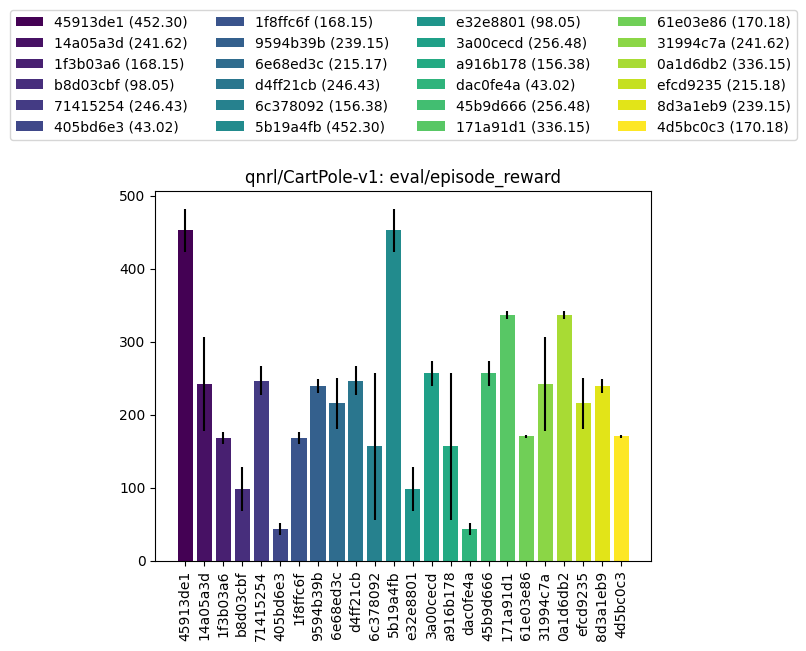

In [178]:
# import numpy as np

# cmap = plt.get_cmap()
# colors_idx = np.linspace(0, 1, len(seedgroups_tree[sweep_name_id['qnrl/CartPole-v1']].items()))

figure_meta = {
    'type': 'bar',
    # 'title': "qnrl/CartPole-v1: eval/episode_reward",
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': runs, 
            # 'color': cmap(colors_idx[i]),
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/CartPole-v1']].items())
    ],
    'ax': {
        'title': "qnrl/CartPole-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

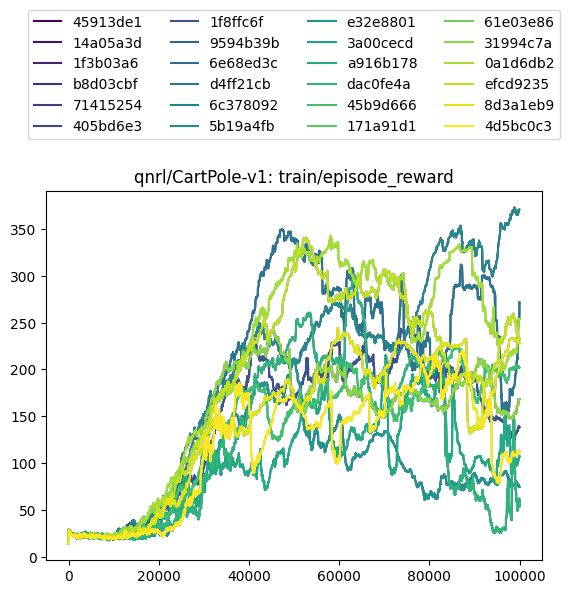

In [148]:
figure_meta = {
    'type': 'line-agg-mean',
    # 'title': "qnrl/CartPole-v1: train/episode_reward",
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': runs, 
            # 'color': cmap(colors_idx[i]),
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 100,
            'fill_between': None,
            # 'fill_between': {
            #     'alpha': 0.3,
            #     'interpolate': True,
            # },
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/CartPole-v1']].items())
    ],
    'ax': {
        'title': "qnrl/CartPole-v1: train/episode_reward",
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    }
    # 'ax': {
    #     'xticks': {
    #         'rotation': 90,
    #     },
    # },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

In [149]:
# data['45913de1']['mean']

keys = list(list(data.keys())[::-1])
values = [data[k]['mean'].iloc[-1] for k in keys]
idx_max = np.argmax(values)
keys[idx_max], values[idx_max], list(zip(keys, values))

('5b19a4fb',
 np.float64(370.6628925120773),
 [('4d5bc0c3', np.float64(110.86018586676482)),
  ('8d3a1eb9', np.float64(228.30357142857144)),
  ('efcd9235', np.float64(232.01397537647534)),
  ('0a1d6db2', np.float64(253.50564935064935)),
  ('31994c7a', np.float64(168.08918834996422)),
  ('61e03e86', np.float64(110.86018586676481)),
  ('171a91d1', np.float64(253.50564935064935)),
  ('45b9d666', np.float64(201.83576388888886)),
  ('dac0fe4a', np.float64(59.16660557184751)),
  ('a916b178', np.float64(107.20327942497755)),
  ('3a00cecd', np.float64(201.8357638888889)),
  ('e32e8801', np.float64(74.4595329984481)),
  ('5b19a4fb', np.float64(370.6628925120773)),
  ('6c378092', np.float64(107.20327942497754)),
  ('d4ff21cb', np.float64(271.78463669950736)),
  ('6e68ed3c', np.float64(232.0139753764754)),
  ('9594b39b', np.float64(228.30357142857144)),
  ('1f8ffc6f', np.float64(138.09541585865117)),
  ('405bd6e3', np.float64(59.16660557184751)),
  ('71415254', np.float64(271.78463669950736)),
  

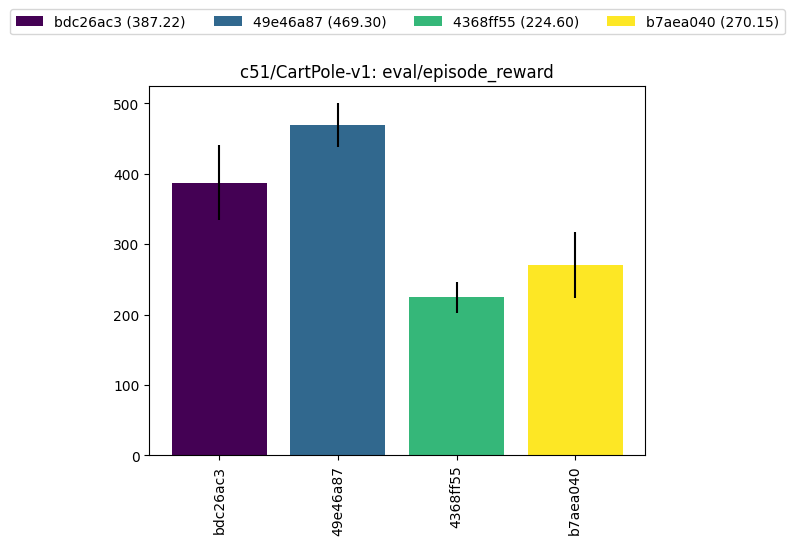

In [177]:
figure_meta = {
    'type': 'bar',
    # 'title': "c51/CartPole-v1: eval/episode_reward",
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['c51/CartPole-v1'], 
            'runs': runs, 
            # 'color': cmap(colors_idx[i]),
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['c51/CartPole-v1']].items())
    ],
    'ax': {
        'title': "c51/CartPole-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

## Ablation: CliffWalking-v1

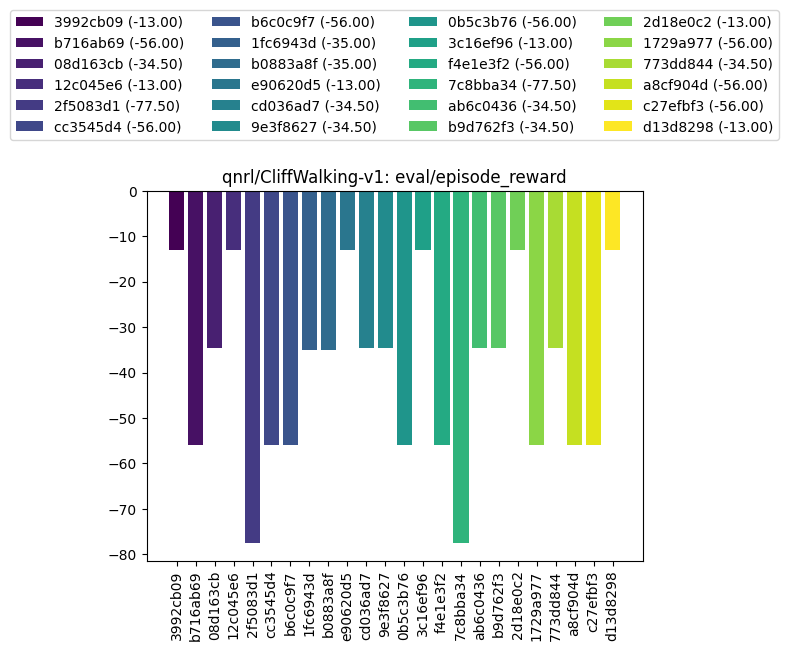

In [176]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/CliffWalking-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/CliffWalking-v1']].items())
    ],
    'ax': {
        'title': "qnrl/CliffWalking-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

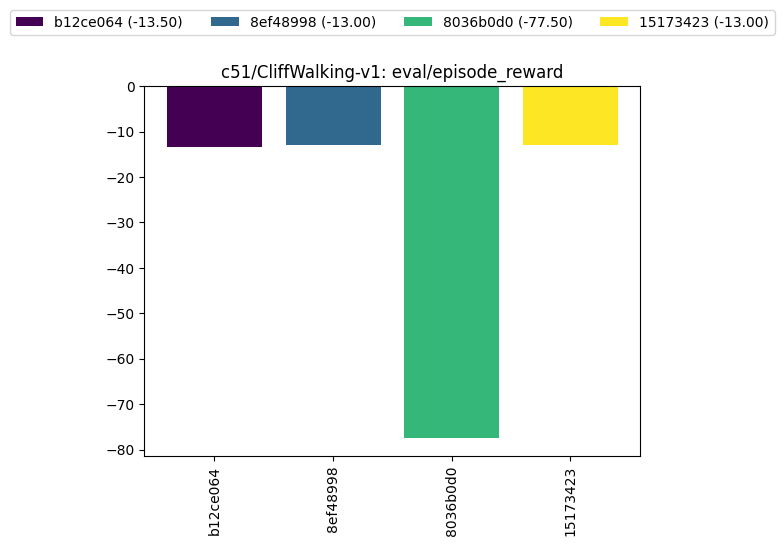

In [175]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['c51/CliffWalking-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['c51/CliffWalking-v1']].items())
    ],
    'ax': {
        'title': "c51/CliffWalking-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

## Ablation: FrozenLake-v1

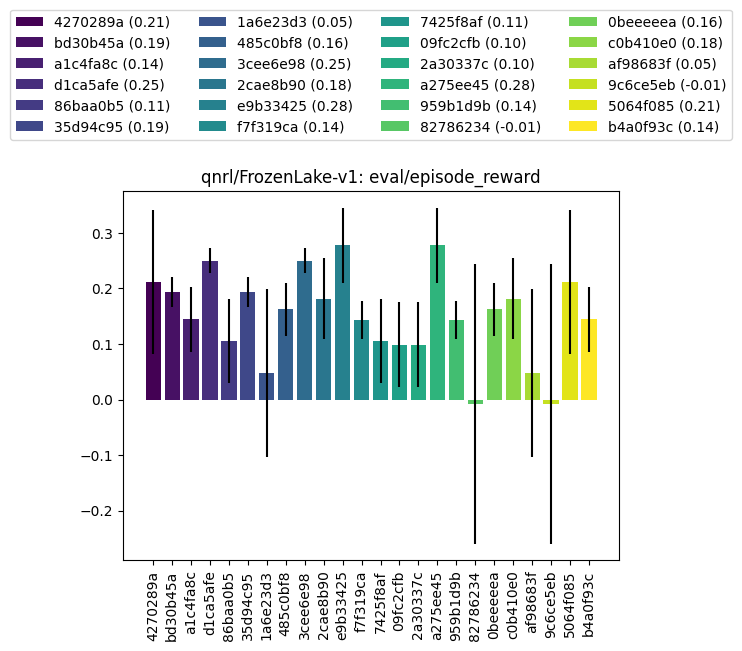

In [174]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/FrozenLake-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/FrozenLake-v1']].items())
    ],
    'ax': {
        'title': "qnrl/FrozenLake-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.04f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

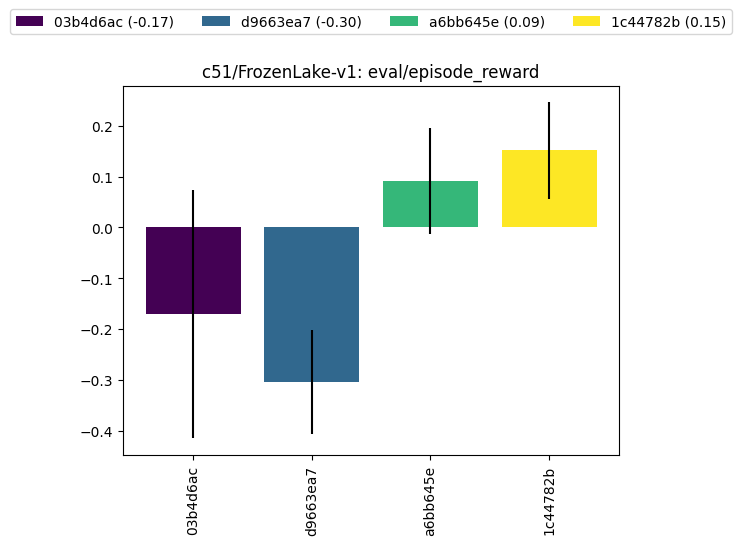

In [173]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['c51/FrozenLake-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['c51/FrozenLake-v1']].items())
    ],
    'ax': {
        'title': "c51/FrozenLake-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.04f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

## Ablation: Acrobot-v1

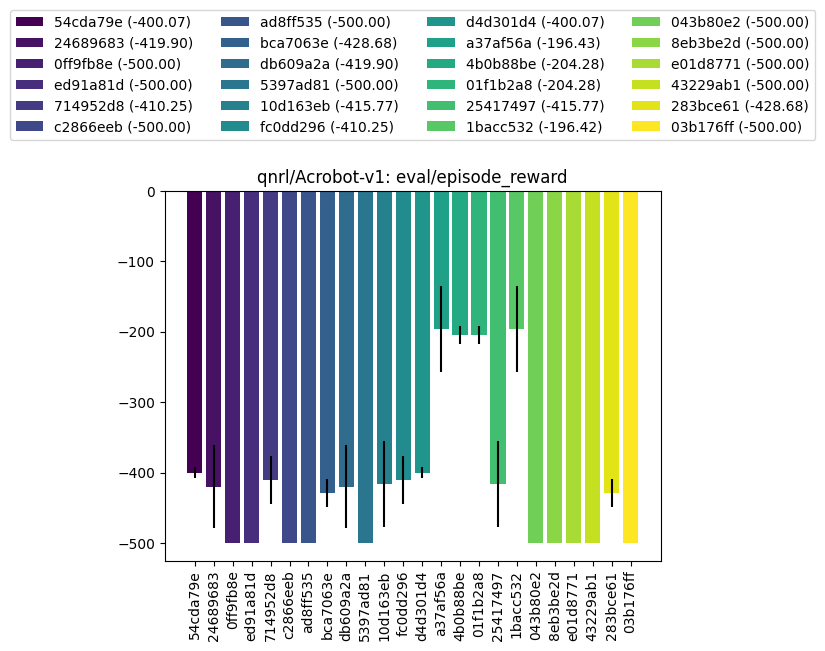

In [169]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/Acrobot-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/Acrobot-v1']].items())
    ],
    'ax': {
        'title': "qnrl/Acrobot-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.04f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)

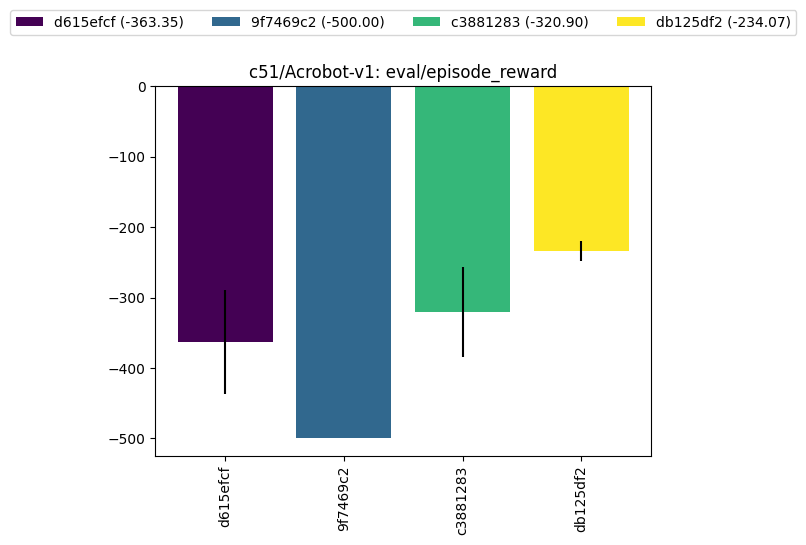

In [172]:
figure_meta = {
    'type': 'bar',
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['c51/Acrobot-v1'], 
            'runs': runs, 
            'zorder': 2,
            'y': 'eval/episode_reward',
            'window': 10,
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['c51/Acrobot-v1']].items())
    ],
    'ax': {
        'title': "c51/Acrobot-v1: eval/episode_reward",
        'xticks': {
            'rotation': 90,
        },
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    },
    # 'bar-label': {
    #     'fmt': '{:,.04f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)